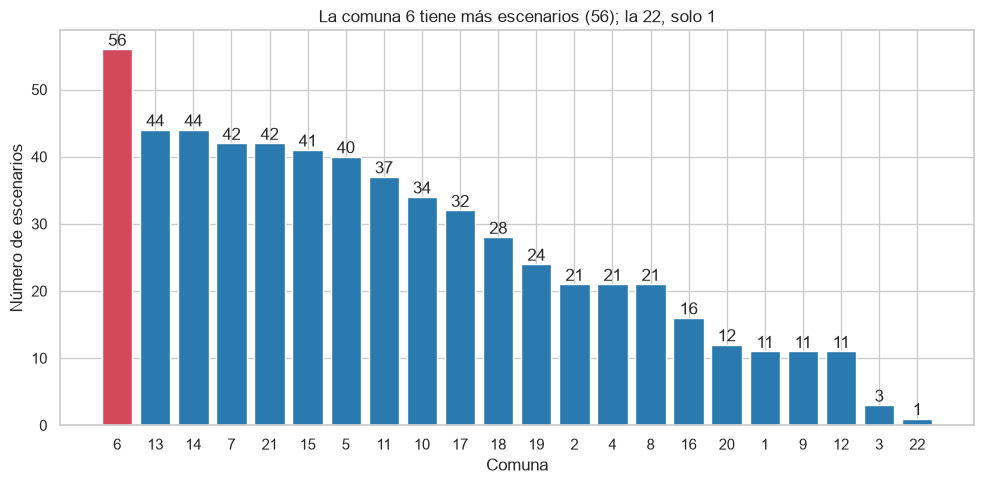

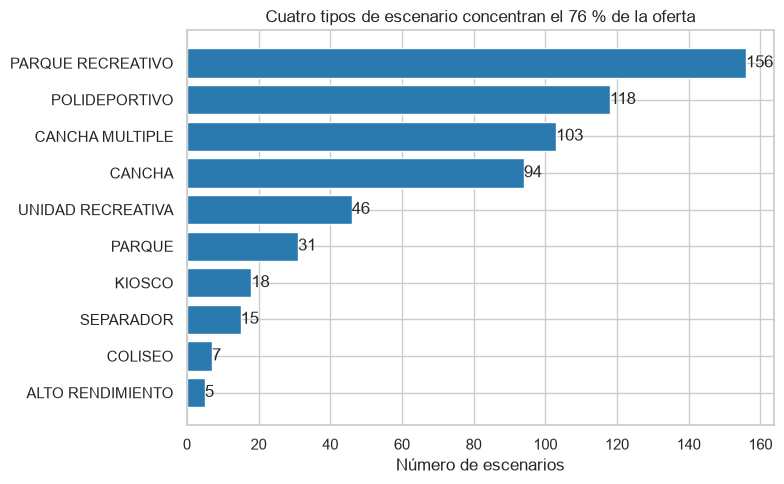

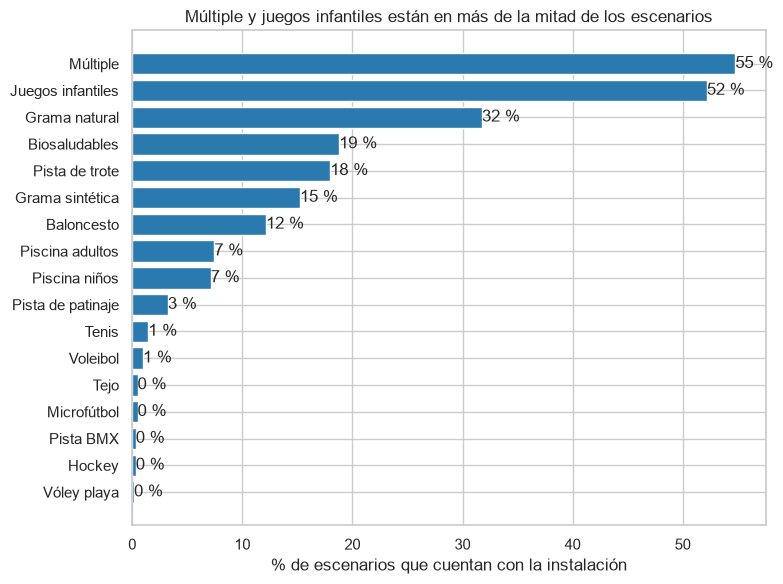

In [1]:
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
AZUL, ROJO = "#2a7ab0", "#d1495b"

df = pd.read_csv("../data/clean/escenarios_deportivos_limpio.csv")
urbano = df[df["zona"] == "Urbana"]
por_comuna = pd.read_csv("../data/clean/escenarios_por_comuna.csv")

cols_inst = ["grama_natural", "sintetica", "multiple", "baloncesto", "voleibol",
             "piscina_adultos", "piscina_ninos", "juegos_infantiles", "biosaludables",
             "pista_patinaje", "pista_de_trote", "pista_bmx", "tenis", "tejo",
             "hockey", "microfutb", "voley_playa"]
nombres = {"grama_natural": "Grama natural", "sintetica": "Grama sintética",
           "multiple": "Múltiple", "baloncesto": "Baloncesto", "voleibol": "Voleibol",
           "piscina_adultos": "Piscina adultos", "piscina_ninos": "Piscina niños",
           "juegos_infantiles": "Juegos infantiles", "biosaludables": "Biosaludables",
           "pista_patinaje": "Pista de patinaje", "pista_de_trote": "Pista de trote",
           "pista_bmx": "Pista BMX", "tenis": "Tenis", "tejo": "Tejo",
           "hockey": "Hockey", "microfutb": "Microfútbol", "voley_playa": "Vóley playa"}

# --- Gráfico 1: escenarios por comuna ---
conteo = urbano["comuna"].value_counts().sort_values(ascending=False)
colores = [ROJO if c == conteo.index[0] else AZUL for c in conteo.index]
fig, ax = plt.subplots(figsize=(10, 5))
barras = ax.bar(conteo.index.astype(str), conteo.values, color=colores)
ax.bar_label(barras)
ax.set_title(f"La comuna {conteo.index[0]} tiene más escenarios ({conteo.iloc[0]}); "
             f"la {conteo.index[-1]}, solo {conteo.iloc[-1]}")
ax.set_xlabel("Comuna")
ax.set_ylabel("Número de escenarios")
plt.tight_layout()
plt.savefig("../reports/figures/escenarios_por_comuna.png", dpi=150)
plt.show()

# --- Gráfico 2: tipos de escenario ---
tipos = df["tipo_escenario"].value_counts()
pct4 = tipos.head(4).sum() / len(df) * 100
top10 = tipos.head(10).sort_values()
fig, ax = plt.subplots(figsize=(8, 5))
barras = ax.barh(top10.index, top10.values, color=AZUL)
ax.bar_label(barras)
ax.set_title(f"Cuatro tipos de escenario concentran el {pct4:.0f} % de la oferta")
ax.set_xlabel("Número de escenarios")
plt.tight_layout()
plt.savefig("../reports/figures/tipos_escenario.png", dpi=150)
plt.show()

# --- Gráfico 3: instalaciones ---
pct = ((df[cols_inst] > 0).mean() * 100).sort_values()
pct.index = [nombres[c] for c in pct.index]
fig, ax = plt.subplots(figsize=(8, 6))
barras = ax.barh(pct.index, pct.values, color=AZUL)
ax.bar_label(barras, fmt="%.0f %%")
ax.set_title(f"{pct.index[-1]} y {pct.index[-2].lower()} están en más de la mitad de los escenarios")
ax.set_xlabel("% de escenarios que cuentan con la instalación")
plt.tight_layout()
plt.savefig("../reports/figures/instalaciones_pct.png", dpi=150)
plt.show()

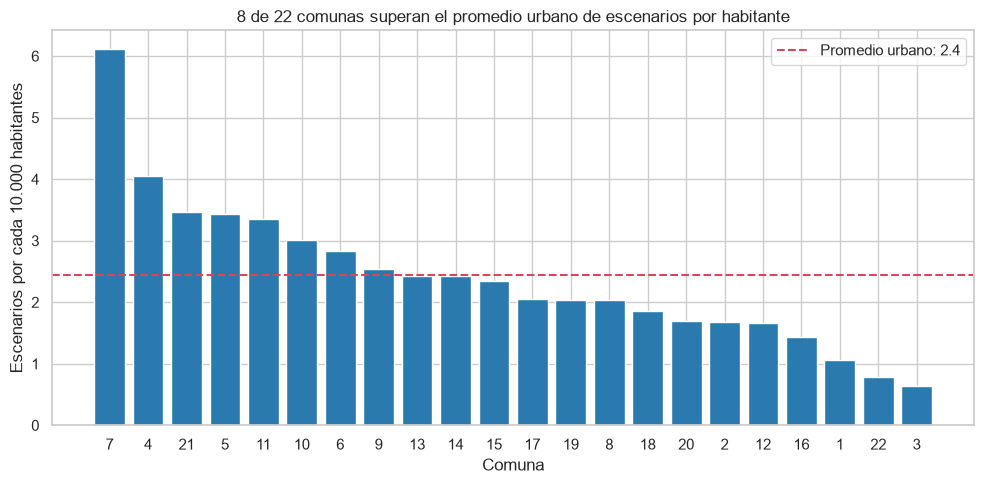

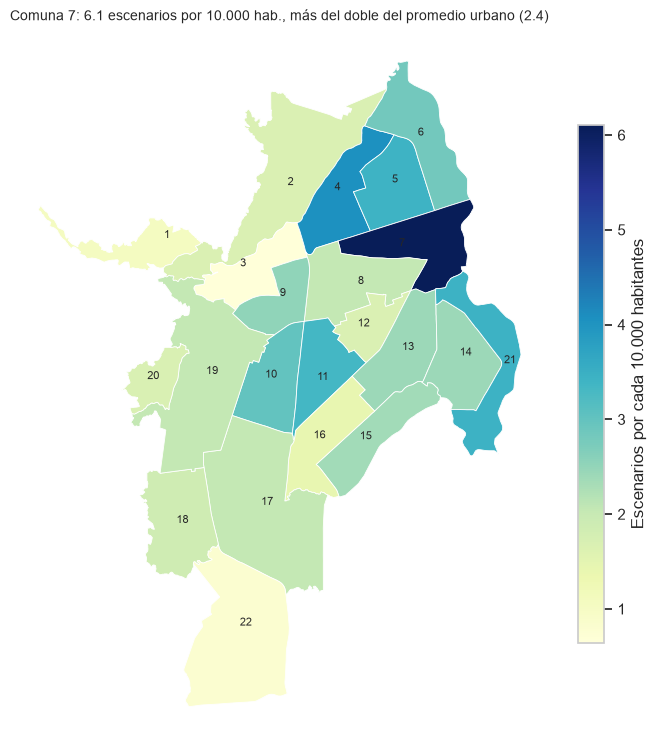

In [2]:
# --- Gráfico 4: ranking por habitante ---
promedio = por_comuna["escenarios"].sum() / por_comuna["poblacion_2020"].sum() * 10000
n_arriba = (por_comuna["esc_por_10k"] > promedio).sum()
orden = por_comuna.sort_values("esc_por_10k", ascending=False)

fig, ax = plt.subplots(figsize=(10, 5))
ax.bar(orden["comuna"].astype(str), orden["esc_por_10k"], color=AZUL)
ax.axhline(promedio, color=ROJO, linestyle="--", label=f"Promedio urbano: {promedio:.1f}")
ax.set_title(f"{n_arriba} de 22 comunas superan el promedio urbano de escenarios por habitante")
ax.set_xlabel("Comuna")
ax.set_ylabel("Escenarios por cada 10.000 habitantes")
ax.legend()
plt.tight_layout()
plt.savefig("../reports/figures/ranking_esc_por_10k.png", dpi=150)
plt.show()

# --- Gráfico 5: mapa ---
ruta_gdb = "../data/raw/DIVIPOLA_2026.gdb"
comunas = gpd.read_file(ruta_gdb, layer="pdt_dpa_comunas")
comunas["comuna"] = comunas["ComCodigo"].astype(str).str.extract(r"(\d+)", expand=False).astype(int)
mapa = comunas.merge(por_comuna, on="comuna", how="left")

mejor = por_comuna.loc[por_comuna["esc_por_10k"].idxmax()]
fig, ax = plt.subplots(figsize=(7, 9))
mapa.plot(column="esc_por_10k", cmap="YlGnBu", edgecolor="white", linewidth=0.6,
          legend=True, legend_kwds={"label": "Escenarios por cada 10.000 habitantes", "shrink": 0.6},
          ax=ax)
for _, f in mapa.iterrows():
    p = f.geometry.representative_point()
    ax.annotate(str(f["comuna"]), (p.x, p.y), ha="center", fontsize=8)
ax.set_title(f"Comuna {int(mejor['comuna'])}: {mejor['esc_por_10k']:.1f} escenarios por 10.000 hab., "
             f"más del doble del promedio urbano ({promedio:.1f})", fontsize=10)
ax.set_axis_off()
plt.tight_layout()
plt.savefig("../reports/figures/mapa_escenarios_por_10k.png", dpi=150)
plt.show()